# Fixed-feature clustering: 10 state variables + S&P 500 return

Use the fixed **five macro/market + five technical + S&P return** specification recorded in `paper/tables/primary_feature_specification.csv`. This set is chosen by economic role, before running this comparison; it is not the highest-scoring randomized draw.

Compare the five model families using the full 85-candidate grid from notebook 02. Select a standard-input winner, inspect its profiles and check fixed-settings PCA95/robust calibrations. No cluster count is inherited from earlier experiments. The final section uses the chosen K-means profiles for EP and Fully Flexible Resampling. Formal profile tests are separate.

Run from the repository folder with its `.venv` Python kernel. Input files were saved by notebook 03; no downloads or repeated feature construction are needed. Fortitudo's [EP/FFR framework](https://github.com/fortitudo-tech/pcrm-book) remains the downstream application.


In [1]:
from pathlib import Path
from time import perf_counter
from itertools import combinations
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             calinski_harabasz_score, davies_bouldin_score,
                             adjusted_rand_score)
from scipy.spatial.distance import pdist, squareform
from kmedoids import KMedoids

sns.set_theme(style="whitegrid", palette="colorblind", font_scale=0.9)
output_dir = Path("data/fixed_feature_clustering")
output_dir.mkdir(parents=True, exist_ok=True)


## Load the fixed inputs

Keep the same 3,630 complete-case dates as the expanded 51-input study. No filling, extra date filtering or recalculation of returns. The S&P return is already a daily log return. The original 50-feature pool supplies the ten state variables.


In [2]:
specification = pd.read_csv("paper/tables/primary_feature_specification.csv")
features = pd.read_csv("data/random_features/feature_pool_50_complete.csv",
                       index_col="date", parse_dates=["date"])
outcomes = pd.read_csv("data/random_features/sp500_outcomes.csv",
                       index_col="date", parse_dates=["date"])

df = features.join(outcomes[["sp500_log_return"]])[specification["feature"]].copy()
display(specification)
df.head()


Out[2]: 
            breakeven_10y  ...  sp500_log_return
date                       ...                  
2011-10-05           1.80  ...          0.017708
2011-10-06           1.88  ...          0.018138
2011-10-07           1.94  ...         -0.008197
2011-10-11           1.95  ...          0.000544
2011-10-12           1.98  ...          0.009747

[5 rows x 11 columns]


,block,feature,transformation
0,macro_market,breakeven_10y,identity
1,macro_market,real_yield_10y,identity
2,macro_market,slope_10y_2y,identity
3,macro_market,baa_10y_spread,identity
4,macro_market,vix,log
5,technical,sp500_momentum_63d,identity
6,technical,sp500_drawdown_252d,identity
7,technical,sp500_realized_vol_21d,log
8,technical,sp500_rsi_14d,identity
9,technical,small_large_momentum_21d,identity


## Selective logs, StandardScaler and PCA

Apply a natural log to **VIX and 21-day realized volatility** only. Other columns retain their saved definitions; momentum and the S&P return already contain log returns. Keep original-unit `df` for profiling.

The primary fit retains **all informative, unwhitened PCs**. This rotates the standardized geometry without truncation. PCA95 is a later sensitivity check; PC1/PC2 plots do not define the fitted dimension.


In [3]:
df_transformed = df.copy()
log_columns = specification.loc[specification["transformation"].eq("log"), "feature"].tolist()
df_transformed[log_columns] = np.log(df_transformed[log_columns])

scaler = StandardScaler()
scaled_df = pd.DataFrame(scaler.fit_transform(df_transformed),
                         index=df.index, columns=df.columns)
pca = PCA(n_components=np.linalg.matrix_rank(scaled_df), svd_solver="full")
data_pca = pd.DataFrame(pca.fit_transform(scaled_df), index=df.index,
                        columns=[f"PC{i + 1}" for i in range(pca.n_components_)])

print(f"{len(df):,} dates | {df.index.min().date()} to {df.index.max().date()}")
print(f"{df.shape[1]} inputs | {data_pca.shape[1]} informative PCs | no missing values: {not df.isna().any().any()}")
display(scaled_df.head())
pca_variance = pd.DataFrame({"Explained variance": pca.explained_variance_ratio_,
                            "Cumulative variance": np.cumsum(pca.explained_variance_ratio_)},
                           index=data_pca.columns)
pca_variance.round(4)


3,630 dates | 2011-10-05 to 2026-10-02
11 inputs | 11 informative PCs | no missing values: True
Out[3]: 
      Explained variance  Cumulative variance
PC1               0.3314               0.3314
PC2               0.2050               0.5364
PC3               0.1028               0.6392
PC4               0.0893               0.7285
PC5               0.0817               0.8103
PC6               0.0619               0.8721
PC7               0.0408               0.9129
PC8               0.0362               0.9491
PC9               0.0242               0.9733
PC10              0.0150               0.9884
PC11              0.0116               1.0000


,breakeven_10y,real_yield_10y,slope_10y_2y,baa_10y_spread,vix,sp500_momentum_63d,sp500_drawdown_252d,sp500_realized_vol_21d,sp500_rsi_14d,small_large_momentum_21d,sp500_log_return
date,,,,,,,,,,,
2011-10-05,-0.794697,-0.474482,1.107784,2.003811,2.599723,-3.142353,-2.432029,1.905528,-0.898390,-0.497683,1.620660
2011-10-06,-0.565296,-0.464127,1.169578,1.966979,2.464291,-2.745701,-2.130287,1.836638,-0.539448,-0.672559,1.661182
2011-10-07,-0.393245,-0.433060,1.268449,1.930147,2.457999,-2.586884,-2.267325,1.830792,-0.695595,-1.005416,-0.819145
2011-10-11,-0.364570,-0.360573,1.342602,1.930147,2.142717,-2.027328,-1.689776,1.879160,-0.057960,-0.433225,0.004084
2011-10-12,-0.278544,-0.329507,1.453831,1.948563,1.980141,-1.767050,-1.521036,1.880657,0.120233,-0.483346,0.870875


## Rules fixed before comparing results

- Search **K = 2–8**; GMM uses the same candidate component counts. This does not test whether a single population is sufficient.
- Require at least two groups, **80% coverage** and at least **1% of all dates (or 20 rows)** in every assigned group. GMM must converge.
- Score all fits in the **same standard-scaled, selectively logged 11-input space**, including calibration checks. Exclude DBSCAN noise and show coverage.
- Select K-means, K-medoids, hierarchical and DBSCAN candidates by silhouette on the **same fixed 1,000 dates**, seed 123, matching notebook 03's scoring recipe. Select GMM by **lowest eligible BIC** in its fixed standard PCA representation.
- Identify the silhouette winner by the highest selection silhouette among these eligible standard-input per-family winners. Show exact full-sample silhouettes afterwards; do not reselect by them. PCA95 and robust scaling remain sensitivity checks, not another search for the score winner.

Calinski–Harabasz and Davies–Bouldin use every assigned date. A higher assigned-only silhouette with lower coverage is not directly equivalent to classifying every date. “Best” below means preferred by this rule among the tested fits, not optimal economic regimes or demonstrated EP usefulness.

The final section compares the silhouette winner with K-means for the EP demonstration. That application choice also considers calibration stability and profile populations; it does not change the recorded tuning winner.


In [4]:
k_values = range(2, 9)
minimum_size = max(20, int(np.ceil(0.01 * len(df))))
score_indices = np.sort(np.random.default_rng(123).choice(len(df), 1000, replace=False))
evaluation_distances = squareform(pdist(scaled_df))
score_distances = evaluation_distances[np.ix_(score_indices, score_indices)]
representations = {"Standard": data_pca.to_numpy()}
fit_distances = {"Standard": evaluation_distances}
rows, assignments = [], {}

print(f"Minimum cluster population: {minimum_size}; silhouette selection dates: {len(score_indices)}")


Minimum cluster population: 37; silhouette selection dates: 1000


### One shared fitting and scoring function

The model grids below stay explicit. This function only fits a supplied model, records its labels and applies the same diagnostics. Parameter dictionaries and labels are retained so the selected fits can be traced to their trials.


In [5]:
def fit_model(name, model, calibration="Standard", stage="Tuning", eps_quantile=np.nan):
    values = representations[calibration]
    fit_values = fit_distances[calibration] if name == "K-medoids" else values
    started = perf_counter()
    model.fit(fit_values)
    seconds = perf_counter() - started
    labels = model.predict(values) if name == "GMM" else model.labels_
    assigned = labels >= 0
    sizes = pd.Series(labels[assigned]).value_counts()
    run = f"run_{len(rows):03d}"
    row = dict(Run=run, Model=name, Stage=stage, Calibration=calibration,
               Fit_dimensions=values.shape[1], Clusters=len(sizes),
               Coverage_pct=100 * assigned.mean(), Noise_rows=int((~assigned).sum()),
               Min_size=int(sizes.min()) if len(sizes) else 0,
               Largest_cluster_pct=100 * sizes.max() / len(labels) if len(sizes) else np.nan,
               Silhouette_sample=np.nan, Calinski_Harabasz=np.nan, Davies_Bouldin=np.nan,
               Fit_seconds=seconds, Parameters=model.get_params().copy(), Eps_quantile=eps_quantile)
    if 2 <= len(sizes) < assigned.sum():
        row["Calinski_Harabasz"] = calinski_harabasz_score(scaled_df.to_numpy()[assigned], labels[assigned])
        row["Davies_Bouldin"] = davies_bouldin_score(scaled_df.to_numpy()[assigned], labels[assigned])
        sample_labels = labels[score_indices]
        keep = sample_labels >= 0
        if 2 <= len(np.unique(sample_labels[keep])) < keep.sum():
            row["Silhouette_sample"] = silhouette_score(
                score_distances[np.ix_(keep, keep)], sample_labels[keep], metric="precomputed")
    row["Eligible"] = (len(sizes) >= 2 and row["Coverage_pct"] >= 80
                       and row["Min_size"] >= minimum_size and np.isfinite(row["Silhouette_sample"]))
    if name == "GMM":
        row.update(K=model.n_components, Covariance=model.covariance_type,
                   BIC=model.bic(values), Converged=bool(model.converged_))
        row["Eligible"] = row["Eligible"] and bool(model.converged_)
    elif name != "DBSCAN":
        row["K"] = model.n_clusters
    rows.append(row)
    assignments[run] = labels
    return row


## Starting configurations

Three clusters for the fixed-count models; DBSCAN starts at eps=3 and min_samples=10. These are diagnostics, not the candidates selected for the primary demonstration.


In [6]:
model_classes = {"K-means": KMeans, "K-medoids": KMedoids,
                 "Agglomerative": AgglomerativeClustering,
                 "GMM": GaussianMixture, "DBSCAN": DBSCAN}
baselines = {
    "K-means": KMeans(n_clusters=3, n_init=10, random_state=1),
    "K-medoids": KMedoids(n_clusters=3, method="fasterpam", init="random", metric="precomputed", random_state=1),
    "Agglomerative": AgglomerativeClustering(n_clusters=3, linkage="ward"),
    "GMM": GaussianMixture(n_components=3, covariance_type="full", n_init=3,
                           max_iter=500, reg_covar=1e-5, random_state=1),
    "DBSCAN": DBSCAN(eps=3, min_samples=10),
}
for name, model in baselines.items():
    fit_model(name, model, stage="Baseline")
pd.DataFrame(rows)[["Model", "Clusters", "Silhouette_sample", "Coverage_pct", "Min_size", "Eligible"]].round(4)


Out[6]: 
           Model  Clusters  Silhouette_sample  Coverage_pct  Min_size  Eligible
0        K-means         3             0.2115      100.0000       722      True
1      K-medoids         3             0.1960      100.0000       857      True
2  Agglomerative         3             0.1857      100.0000       680      True
3            GMM         3             0.1770      100.0000       915      True
4         DBSCAN         1                NaN       99.3664      3607     False


## 1. K-means: seven candidates


In [7]:
for k in k_values:
    fit_model("K-means", KMeans(n_clusters=k, n_init=20, random_state=1))


## 2. K-medoids: fourteen candidates

FasterPAM uses precomputed Euclidean distances; try two initialization seeds.


In [8]:
for k in k_values:
    for seed in [1, 7]:
        fit_model("K-medoids", KMedoids(n_clusters=k, method="fasterpam", init="random",
                                        metric="precomputed", random_state=seed))


## 3. Agglomerative: twenty-one candidates


In [9]:
for method in ["ward", "average", "complete"]:
    for k in k_values:
        fit_model("Agglomerative", AgglomerativeClustering(n_clusters=k, linkage=method))


## 4. Gaussian mixtures: twenty-eight candidates

Compare BIC within this fixed PCA coordinate system. Diagonal covariance depends on the coordinate basis. Convergence and minimum hard-assignment group sizes are required.


In [10]:
for covariance in ["full", "tied", "diag", "spherical"]:
    for k in k_values:
        fit_model("GMM", GaussianMixture(n_components=k, covariance_type=covariance,
                                         n_init=3, max_iter=500, reg_covar=1e-5, random_state=1))


## 5. DBSCAN: fifteen candidates

Use neighbour-distance quantiles to set eps separately for each min_samples. Noise is excluded from profile/geometry calculations and retained as -1 in the saved assignments.


In [11]:
for min_samples in [5, 10, 20]:
    neighbours = NearestNeighbors(n_neighbors=min_samples).fit(data_pca)
    distances = neighbours.kneighbors(data_pca)[0][:, -1]
    for quantile in [0.50, 0.65, 0.80, 0.90, 0.95]:
        eps = float(np.quantile(distances, quantile))
        fit_model("DBSCAN", DBSCAN(eps=eps, min_samples=min_samples), eps_quantile=quantile)

trials = pd.DataFrame(rows).query("Stage == 'Tuning'").copy()
trials.groupby("Model").agg(Candidates=("Run", "size"), Eligible=("Eligible", "sum"))


Out[11]: 
               Candidates  Eligible
Model                              
Agglomerative          21         7
DBSCAN                 15         1
GMM                    28        28
K-means                 7         7
K-medoids              14        14


## Per-model selections and silhouette winner

A failed grid stays unavailable. Use the same population rules for every method, including hierarchies that can otherwise isolate a few extreme dates with a high silhouette.


In [12]:
selected_rows = []
for name in model_classes:
    eligible = trials.loc[trials["Model"].eq(name) & trials["Eligible"]]
    if eligible.empty:
        selected_rows.append({"Model": name, "Eligible": False, "Reason": "No eligible grid candidate"})
    else:
        criterion = "BIC" if name == "GMM" else "Silhouette_sample"
        best = eligible.sort_values(criterion, ascending=name == "GMM", kind="stable").iloc[0]
        selected_rows.append(best.to_dict())
selected = pd.DataFrame(selected_rows)
score_winner = selected.loc[selected["Eligible"]].sort_values("Silhouette_sample", ascending=False, kind="stable").iloc[0]
score_winner_labels = assignments[score_winner["Run"]]

summary_columns = ["Model", "Clusters", "Silhouette_sample", "Calinski_Harabasz",
                   "Davies_Bouldin", "Min_size", "Coverage_pct", "Eligible"]
display(selected[summary_columns].round(4))
print(f"Silhouette winner: {score_winner['Model']}, K={int(score_winner['Clusters'])}, Standard inputs")
print("Parameters:", score_winner["Parameters"])


Silhouette winner: Agglomerative, K=2, Standard inputs
Parameters: {'compute_distances': False, 'compute_full_tree': 'auto', 'connectivity': None, 'distance_threshold': None, 'linkage': 'complete', 'memory': None, 'metric': 'euclidean', 'n_clusters': 2}


,Model,Clusters,Silhouette_sample,Calinski_Harabasz,Davies_Bouldin,Min_size,Coverage_pct,Eligible
0,K-means,2,0.2691,992.6237,1.7073,930,100.000,True
1,K-medoids,2,0.1998,742.2844,2.0037,1486,100.000,True
2,Agglomerative,2,0.3280,414.6569,1.4251,209,100.000,True
3,GMM,8,0.1634,492.3112,1.9597,97,100.000,True
4,DBSCAN,4,0.0437,102.2167,1.6277,37,82.011,True


### The whole grid

Black crosses mark candidates failing the common eligibility rules. GMM's panel uses BIC; the others use selection silhouette. DBSCAN coverage is shown separately.


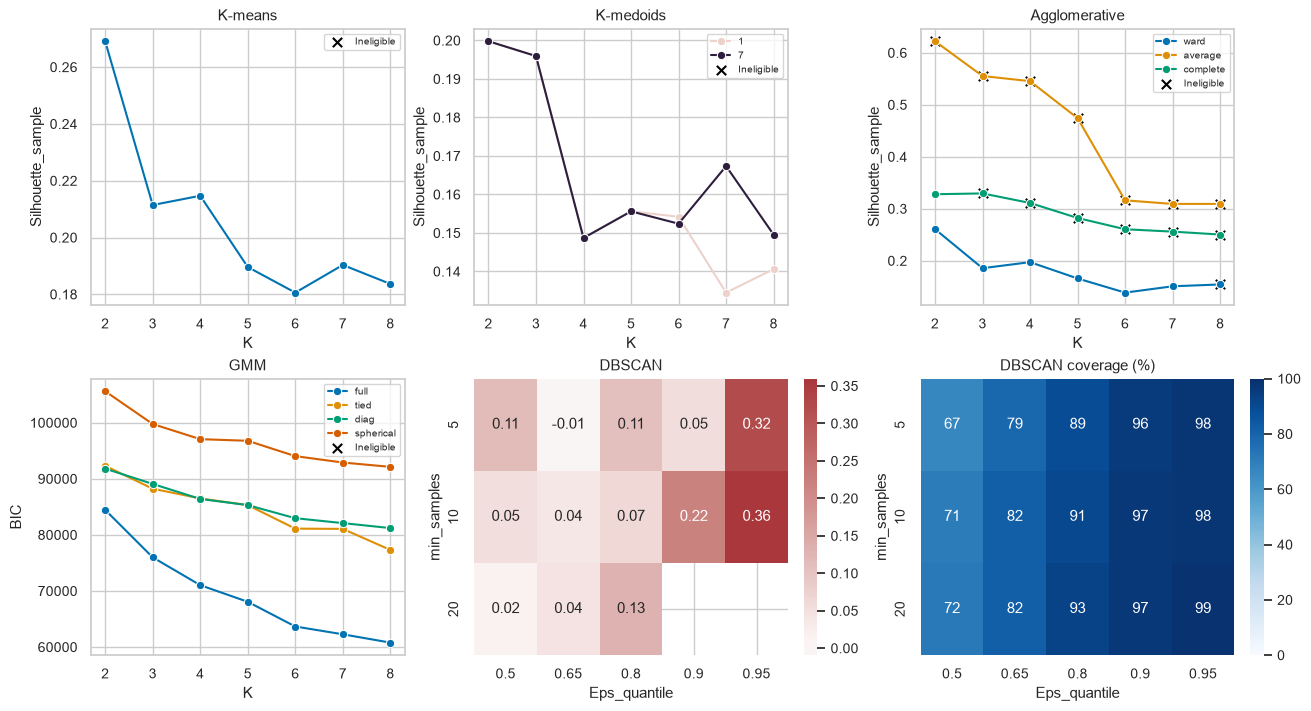

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7), layout="constrained")
for ax, name in zip(axes.flat, model_classes):
    table = trials.loc[trials["Model"].eq(name)].copy()
    if name == "DBSCAN":
        table["min_samples"] = table["Parameters"].map(lambda p: p["min_samples"])
        sns.heatmap(table.pivot(index="min_samples", columns="Eps_quantile", values="Silhouette_sample"),
                    annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
    else:
        metric = "BIC" if name == "GMM" else "Silhouette_sample"
        hue = None
        if name == "Agglomerative":
            table["Linkage"] = table["Parameters"].map(lambda p: p["linkage"])
            hue = "Linkage"
        elif name == "K-medoids":
            table["Seed"] = table["Parameters"].map(lambda p: p["random_state"])
            hue = "Seed"
        elif name == "GMM":
            hue = "Covariance"
        sns.lineplot(data=table, x="K", y=metric, hue=hue, marker="o", ax=ax)
        rejected = table.loc[~table["Eligible"]]
        ax.scatter(rejected["K"], rejected[metric], marker="x", color="black", s=45, label="Ineligible")
        ax.legend(fontsize=7)
    ax.set_title(name)
db_trials = trials.loc[trials["Model"].eq("DBSCAN")].copy()
db_trials["min_samples"] = db_trials["Parameters"].map(lambda p: p["min_samples"])
sns.heatmap(db_trials.pivot(index="min_samples", columns="Eps_quantile", values="Coverage_pct"),
            annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, ax=axes.flat[-1])
axes.flat[-1].set_title("DBSCAN coverage (%)")
fig.savefig(output_dir / "tuning_grid.png", dpi=160)
plt.show()


## Sensitivity checks: PCA95 and robust scaling

Keep each eligible standard winner's settings and cluster count. DBSCAN recalculates eps from its selected neighbour-distance quantile in each representation. These rows do not replace the primary selection. BIC values across different representations are not compared.


In [14]:
pca95_count = int(np.searchsorted(pca_variance["Cumulative variance"], 0.95) + 1)
robust_values = RobustScaler().fit_transform(df_transformed)
robust_pca = PCA(n_components=np.linalg.matrix_rank(robust_values - robust_values.mean(axis=0)), svd_solver="full")
representations["PCA95"] = data_pca.iloc[:, :pca95_count].to_numpy()
representations["Robust"] = robust_pca.fit_transform(robust_values)
for calibration in ["PCA95", "Robust"]:
    values = representations[calibration]
    fit_distances[calibration] = squareform(pdist(values))
    for _, winner in selected.loc[selected["Eligible"]].iterrows():
        name = winner["Model"]
        params = winner["Parameters"].copy()
        if name == "DBSCAN":
            neighbours = NearestNeighbors(n_neighbors=params["min_samples"]).fit(values)
            distances = neighbours.kneighbors(values)[0][:, -1]
            params["eps"] = float(np.quantile(distances, winner["Eps_quantile"]))
        row = fit_model(name, model_classes[name](**params), calibration, "Calibration", winner["Eps_quantile"])
        labels = assignments[row["Run"]]
        reference = assignments[winner["Run"]]
        common = (labels >= 0) & (reference >= 0)
        row["ARI_vs_standard"] = adjusted_rand_score(reference[common], labels[common])
        row["Shared_assigned_pct"] = 100 * common.mean()

calibrations = pd.DataFrame(rows).query("Stage == 'Calibration'")
display(pd.DataFrame({"Fit dimensions": {name: x.shape[1] for name, x in representations.items()}}))
calibrations[["Model", "Calibration", "Clusters", "Silhouette_sample", "Min_size",
              "Coverage_pct", "ARI_vs_standard", "Eligible"]].round(4)


Out[14]: 
            Model Calibration  ...  ARI_vs_standard  Eligible
90        K-means       PCA95  ...           1.0000      True
91      K-medoids       PCA95  ...           0.9413      True
92  Agglomerative       PCA95  ...           0.0577     False
93            GMM       PCA95  ...           0.7109      True
94         DBSCAN       PCA95  ...           0.3414     False
95        K-means      Robust  ...           0.8362      True
96      K-medoids      Robust  ...           0.1203      True
97  Agglomerative      Robust  ...           0.2542     False
98            GMM      Robust  ...           0.5806      True
99         DBSCAN      Robust  ...           0.2551     False

[10 rows x 8 columns]


,Fit dimensions
Standard,11
PCA95,9
Robust,11


## Initialization checks

Refit the selected standard K-means, K-medoids and GMM configurations with seeds 1, 7 and 21. These checks measure initialization sensitivity, not robustness to feature choices or new histories.


In [15]:
seed_rows = []
for name in ["K-means", "K-medoids", "GMM"]:
    winner = selected.loc[selected["Model"].eq(name) & selected["Eligible"]]
    if winner.empty:
        continue
    winner = winner.iloc[0]
    seed_labels, eligibility = [], []
    for seed in [1, 7, 21]:
        params = dict(winner["Parameters"], random_state=seed)
        row = fit_model(name, model_classes[name](**params), stage="Seed check")
        row["Seed"] = seed
        seed_labels.append(assignments[row["Run"]])
        eligibility.append(row["Eligible"])
    agreements = [adjusted_rand_score(a, b) for a, b in combinations(seed_labels, 2)]
    seed_rows.append({"Model": name, "Mean_ARI": np.mean(agreements),
                      "Minimum_ARI": np.min(agreements), "All_eligible": all(eligibility)})
seed_summary = pd.DataFrame(seed_rows)
seed_summary.round(4)


Out[15]: 
       Model  Mean_ARI  Minimum_ARI  All_eligible
0    K-means     1.000        1.000          True
1  K-medoids     1.000        1.000          True
2        GMM     0.864        0.796          True


## Summary table: exact silhouettes as a check

Calculate full assigned-sample silhouette for the baseline, selected and calibration configurations. Selection still uses the fixed 1,000-date criterion above. The final row of the notebook repeats the main five-model table for easy reference.


In [16]:
comparison = pd.DataFrame(rows).query("Stage != 'Tuning' and Stage != 'Seed check'").copy()
comparison = pd.concat([comparison, selected.loc[selected["Eligible"]].assign(Stage="Selected")], ignore_index=True)
comparison["Silhouette_full"] = np.nan
for i, row in comparison.iterrows():
    labels = assignments[row["Run"]]
    keep = labels >= 0
    if 2 <= len(np.unique(labels[keep])) < keep.sum():
        comparison.loc[i, "Silhouette_full"] = silhouette_score(
            evaluation_distances[np.ix_(keep, keep)], labels[keep], metric="precomputed")
selected["Silhouette_full"] = selected["Run"].map(comparison.set_index("Run")["Silhouette_full"])
selected["Seed_stability_ARI"] = selected["Model"].map(seed_summary.set_index("Model")["Mean_ARI"])
final_columns = ["Model", "Clusters", "Silhouette_sample", "Silhouette_full", "Calinski_Harabasz",
                 "Davies_Bouldin", "Coverage_pct", "Min_size", "Seed_stability_ARI", "Eligible"]
display(selected[final_columns].round(4))
comparison[["Model", "Stage", "Calibration", "Fit_dimensions", "Clusters", "Silhouette_sample",
            "Silhouette_full", "Coverage_pct", "Min_size", "Eligible"]].round(4)


Out[16]: 
            Model        Stage Calibration  ...  Coverage_pct  Min_size  Eligible
0         K-means     Baseline    Standard  ...      100.0000       722      True
1       K-medoids     Baseline    Standard  ...      100.0000       857      True
2   Agglomerative     Baseline    Standard  ...      100.0000       680      True
3             GMM     Baseline    Standard  ...      100.0000       915      True
4          DBSCAN     Baseline    Standard  ...       99.3664      3607     False
5         K-means  Calibration       PCA95  ...      100.0000       930      True
6       K-medoids  Calibration       PCA95  ...      100.0000      1508      True
7   Agglomerative  Calibration       PCA95  ...      100.0000         7     False
8             GMM  Calibration       PCA95  ...      100.0000        94      True
9          DBSCAN  Calibration       PCA95  ...       82.1212        20     False
10        K-means  Calibration      Robust  ...      100.0000       791      True
11    

,Model,Clusters,Silhouette_sample,Silhouette_full,Calinski_Harabasz,Davies_Bouldin,Coverage_pct,Min_size,Seed_stability_ARI,Eligible
0,K-means,2,0.2691,0.2725,992.6237,1.7073,100.000,930,1.000,True
1,K-medoids,2,0.1998,0.1944,742.2844,2.0037,100.000,1486,1.000,True
2,Agglomerative,2,0.3280,0.3321,414.6569,1.4251,100.000,209,NaN,True
3,GMM,8,0.1634,0.1611,492.3112,1.9597,100.000,97,0.864,True
4,DBSCAN,4,0.0437,0.0419,102.2167,1.6277,82.011,37,NaN,True


## Silhouette winner: PCA view, date assignments and silhouette distribution

Fit labels use all informative coordinates. Overlap in PC1/PC2 does not demonstrate overlap in the full fitted space. Cluster IDs are local categories and are not reordered by return means. Any DBSCAN noise appears in grey and is excluded from its financial profiles.


Negative individual silhouettes: 6.2% of assigned dates


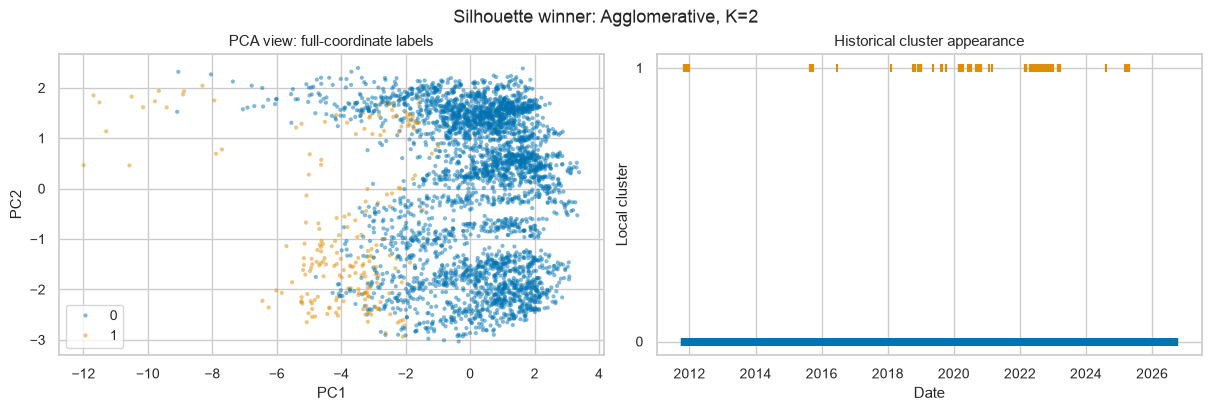

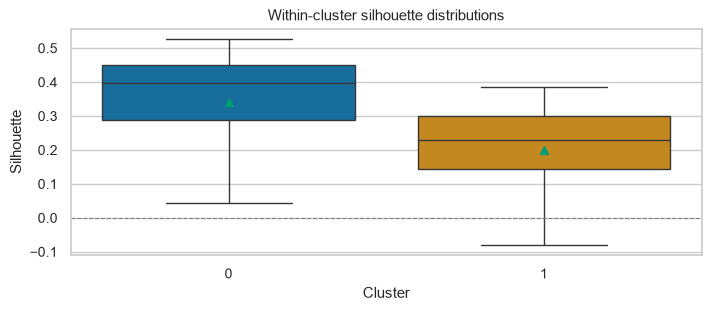

In [17]:
profile = df.assign(Cluster=score_winner_labels)
assigned_profile = profile.loc[profile["Cluster"].ge(0)]
cluster_order = sorted(assigned_profile["Cluster"].unique())
palette = dict(zip(cluster_order, sns.color_palette("colorblind", len(cluster_order))))
palette[-1] = "grey"

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
sns.scatterplot(x=data_pca["PC1"], y=data_pca["PC2"], hue=score_winner_labels,
                palette=palette, s=9, linewidth=0, alpha=0.5, ax=axes[0])
axes[0].set(title="PCA view: full-coordinate labels", xlabel="PC1", ylabel="PC2")
for cluster in sorted(profile["Cluster"].unique()):
    dates = profile.index[profile["Cluster"].eq(cluster)]
    axes[1].scatter(dates, np.repeat(cluster, len(dates)), color=palette[cluster], marker="|", s=40)
axes[1].set(title="Historical cluster appearance", xlabel="Date", ylabel="Local cluster",
            yticks=sorted(profile["Cluster"].unique()))
fig.suptitle(f"Silhouette winner: {score_winner['Model']}, K={int(score_winner['Clusters'])}")
fig.savefig(output_dir / "selected_model_views.png", dpi=160)
plt.show()

keep = score_winner_labels >= 0
sample_silhouettes = silhouette_samples(evaluation_distances[np.ix_(keep, keep)],
                                        score_winner_labels[keep], metric="precomputed")
silhouette_details = pd.DataFrame({"Cluster": score_winner_labels[keep], "Silhouette": sample_silhouettes},
                                  index=df.index[keep])
fig, ax = plt.subplots(figsize=(7, 3), layout="constrained")
sns.boxplot(data=silhouette_details, x="Cluster", y="Silhouette", hue="Cluster",
            palette="colorblind", legend=False, showmeans=True, showfliers=False, ax=ax)
ax.axhline(0, color="grey", linestyle="--", linewidth=0.8)
ax.set_title("Within-cluster silhouette distributions")
fig.savefig(output_dir / "selected_silhouettes.png", dpi=160)
plt.show()
print(f"Negative individual silhouettes: {100 * (sample_silhouettes < 0).mean():.1f}% of assigned dates")


## Original-unit cluster profiles

The labels come from the selected model, not from the plotting coordinates. Profile the saved original features, without an inverse PCA reconstruction. Boxplot whiskers hide fliers for readability, but tables retain all assigned observations. Returns, momentum, drawdown and relative momentum are displayed in percent; realized volatility remains its saved annualized-percent measure.


,Rows,Share_all_dates_pct
Cluster,,
0,3421,94.24
1,209,5.76


Mean            Median               Std         
Cluster                         0        1        0        1        0        1
breakeven_10y              2.0760   2.0965   2.1600   2.2400   0.3338   0.5369
real_yield_10y             0.5835   0.4916   0.4800   0.5500   0.9711   0.8684
slope_10y_2y               0.8099   0.1811   0.7500   0.1900   0.8059   0.6054
baa_10y_spread             2.2627   2.4225   2.1900   2.2600   0.5427   0.5258
vix                       17.1039  31.3878  15.9600  28.7100   5.3156  10.4805
sp500_momentum_63d         0.0367  -0.0599   0.0415  -0.0575   0.0560   0.0976
sp500_drawdown_252d       -0.0302  -0.1535  -0.0140  -0.1544   0.0403   0.0635
sp500_realized_vol_21d    13.1501  28.4932  11.4053  24.0665   7.3878  16.6780
sp500_rsi_14d             56.7897  40.2385  58.0628  40.0506  10.4628   8.9963
small_large_momentum_21d  -0.0024  -0.0117  -0.0016  -0.0072   0.0289   0.0415
sp500_log_return           0.0016  -0.0167   0.0010  -0.0136   0.0090   0.0180

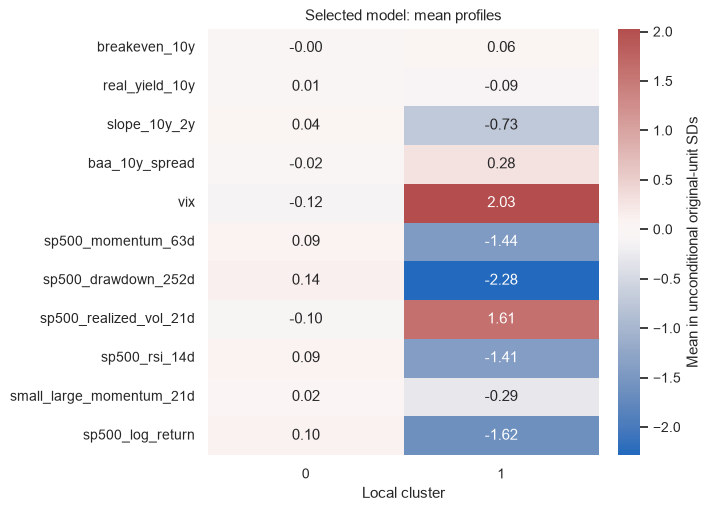

In [18]:
groups = assigned_profile.groupby("Cluster")
cluster_sizes = groups.size().to_frame("Rows")
cluster_sizes["Share_all_dates_pct"] = 100 * cluster_sizes["Rows"] / len(df)
profile_means = groups[df.columns].mean()
profile_stds = groups[df.columns].std(ddof=0)
profile_medians = groups[df.columns].median()
display(cluster_sizes.round(2))
display(pd.concat({"Mean": profile_means.T, "Median": profile_medians.T,
                   "Std": profile_stds.T}, axis=1).round(4))

mean_z = (profile_means - df.mean()) / df.std(ddof=0)
fig, ax = plt.subplots(figsize=(7, 5), layout="constrained")
sns.heatmap(mean_z.T, cmap="vlag", center=0, annot=True, fmt=".2f", ax=ax,
            cbar_kws={"label": "Mean in unconditional original-unit SDs"})
ax.set(title="Selected model: mean profiles", xlabel="Local cluster", ylabel="")
fig.savefig(output_dir / "selected_profile_heatmap.png", dpi=160)
plt.show()


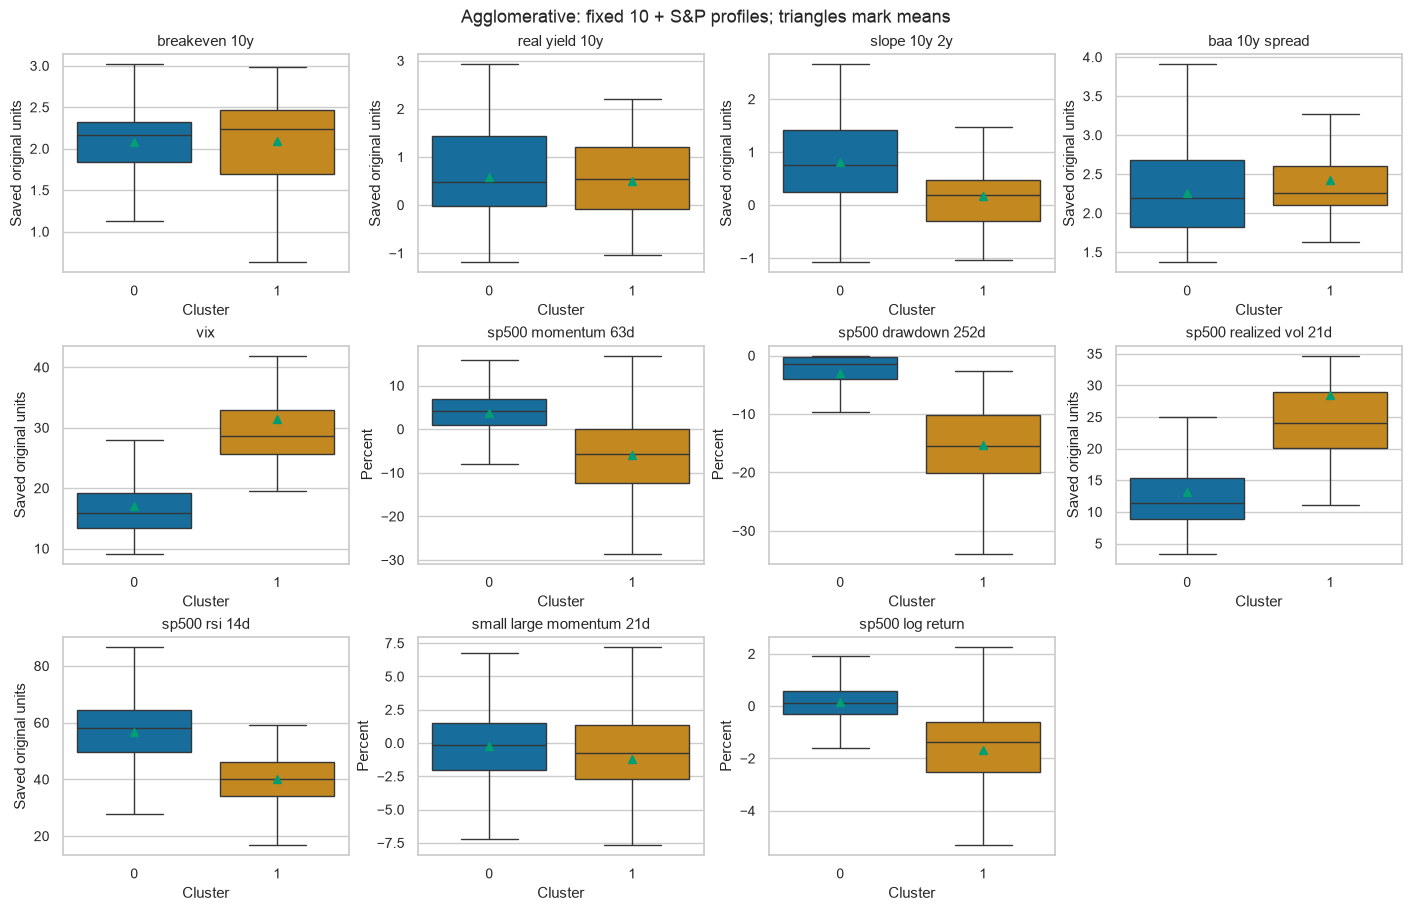

In [19]:
plot_profile = assigned_profile.copy()
percent_columns = ["sp500_log_return", "sp500_momentum_63d", "sp500_drawdown_252d", "small_large_momentum_21d"]
plot_profile[percent_columns] *= 100
fig, axes = plt.subplots(3, 4, figsize=(14, 9), layout="constrained")
for ax, variable in zip(axes.flat, df.columns):
    sns.boxplot(data=plot_profile, x="Cluster", y=variable, hue="Cluster",
                palette="colorblind", legend=False, showmeans=True, showfliers=False, ax=ax)
    ax.set(title=variable.replace("_", " "), xlabel="Cluster",
           ylabel="Percent" if variable in percent_columns else "Saved original units")
for ax in axes.flat[df.shape[1]:]:
    ax.set_visible(False)
fig.suptitle(f"{score_winner['Model']}: fixed 10 + S&P profiles; triangles mark means")
fig.savefig(output_dir / "selected_profile_boxplots.png", dpi=160)
plt.show()


## Equity distribution and risk profiles

Keep the log-return mean explicit. Compute financial risk profiles on **daily simple returns** with `expm1`. CVaR is a positive-loss measure (it can be negative if even the worst outcomes are gains): average the worst 10%/5% losses, with a fractional boundary observation so exactly the required tail mass is used. These are empirical profile summaries, not hypothesis tests or confidence intervals.


,Rows,Mean log return (%),Mean simple return (%),Daily simple volatility (%),Loss probability (%),CVaR 90 (%),CVaR 95 (%)
Cluster,,,,,,,
0,3421,0.155,0.160,0.905,42.882,1.358,1.705
1,209,-1.673,-1.644,1.738,89.952,5.128,6.378


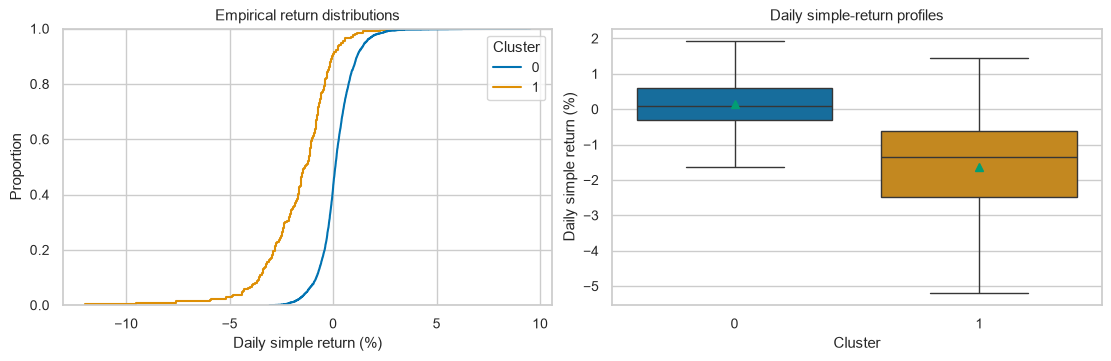

In [20]:
def empirical_cvar(returns, alpha):
    losses = np.sort(-np.asarray(returns))[::-1]
    tail_mass = len(losses) * (1 - alpha)
    whole = int(np.floor(tail_mass))
    fraction = tail_mass - whole
    return (losses[:whole].sum() + fraction * losses[whole]) / tail_mass

risk_rows = []
for cluster, values in groups:
    log_returns = values["sp500_log_return"]
    simple_returns = np.expm1(log_returns)
    risk_rows.append({"Cluster": cluster, "Rows": len(values),
        "Mean log return (%)": 100 * log_returns.mean(),
        "Mean simple return (%)": 100 * simple_returns.mean(),
        "Daily simple volatility (%)": 100 * simple_returns.std(ddof=0),
        "Loss probability (%)": 100 * simple_returns.lt(0).mean(),
        "CVaR 90 (%)": 100 * empirical_cvar(simple_returns, 0.90),
        "CVaR 95 (%)": 100 * empirical_cvar(simple_returns, 0.95)})
risk_summary = pd.DataFrame(risk_rows).set_index("Cluster")
display(risk_summary.round(3))

simple_profile = assigned_profile[["Cluster"]].copy()
simple_profile["Daily simple return (%)"] = 100 * np.expm1(assigned_profile["sp500_log_return"])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
sns.ecdfplot(data=simple_profile, x="Daily simple return (%)", hue="Cluster", palette=palette, ax=axes[0])
sns.boxplot(data=simple_profile, x="Cluster", y="Daily simple return (%)", hue="Cluster",
            palette="colorblind", legend=False, showmeans=True, showfliers=False, ax=axes[1])
axes[0].set_title("Empirical return distributions")
axes[1].set_title("Daily simple-return profiles")
fig.savefig(output_dir / "selected_equity_profiles.png", dpi=160)
plt.show()


## Save outputs and finish with the summary

All 85 trials, parameters, labels, selections, calibration checks and seed checks are saved locally. The notebook contains the executed tables and figures. Results are full-sample descriptions on the fixed calendar. Statistical profile differences, feature robustness and improvements in EP calibration require their separate evaluations; a coarse selected K does not establish a true regime count.


In [21]:
all_fits = pd.DataFrame(rows)
for filename, table in {"all_fits": all_fits, "all_tuning_trials": trials,
                        "selected_models": selected, "model_comparison": comparison,
                        "initialization_stability": seed_summary, "cluster_sizes": cluster_sizes,
                        "profile_means": profile_means, "profile_medians": profile_medians,
                        "profile_stds": profile_stds, "equity_profiles": risk_summary,
                        "pca_variance": pca_variance, "silhouette_details": silhouette_details}.items():
    table.to_csv(output_dir / f"{filename}.csv", index=filename in ["cluster_sizes", "profile_means", "profile_medians",
                                                                  "profile_stds", "equity_profiles", "pca_variance", "silhouette_details"])
pd.DataFrame(assignments, index=df.index).to_csv(output_dir / "all_assignments.csv", index_label="date")
profile[["Cluster"]].to_csv(output_dir / "score_winner_assignments.csv", index_label="date")
specification.to_csv(output_dir / "feature_specification.csv", index=False)
pd.Series(df.index[score_indices], name="date").to_csv(output_dir / "selection_score_dates.csv", index=False)
settings = {"features": df.columns.tolist(), "log_columns": log_columns, "rows": len(df),
            "start": str(df.index.min().date()), "end": str(df.index.max().date()),
            "k_values": list(k_values), "minimum_cluster_rows": minimum_size, "minimum_coverage_pct": 80,
            "score_rows": len(score_indices), "score_seed": 123, "score_winner_run": score_winner["Run"],
            "score_winner_model": score_winner["Model"], "score_winner_parameters": score_winner["Parameters"],
            "selection": "sample silhouette of eligible standard per-family winners; GMM winner chosen by BIC",
            "calibrations": "PCA95 and robust: standard winners settings held fixed; no reselection",
            "validation": "full-sample descriptive clustering; downstream EP outputs saved separately; no formal hypothesis tests"}
(output_dir / "settings.json").write_text(json.dumps(settings, indent=2))
print(f"Silhouette winner: {score_winner['Model']}, K={int(score_winner['Clusters'])}; {len(trials)} tuning candidates")
display(selected[final_columns].round(4))

display(selected[["Model", "Parameters", "BIC"]])


Silhouette winner: Agglomerative, K=2; 85 tuning candidates


,Model,Clusters,Silhouette_sample,Silhouette_full,Calinski_Harabasz,Davies_Bouldin,Coverage_pct,Min_size,Seed_stability_ARI,Eligible
0,K-means,2,0.2691,0.2725,992.6237,1.7073,100.000,930,1.000,True
1,K-medoids,2,0.1998,0.1944,742.2844,2.0037,100.000,1486,1.000,True
2,Agglomerative,2,0.3280,0.3321,414.6569,1.4251,100.000,209,NaN,True
3,GMM,8,0.1634,0.1611,492.3112,1.9597,100.000,97,0.864,True
4,DBSCAN,4,0.0437,0.0419,102.2167,1.6277,82.011,37,NaN,True


,Model,Parameters,BIC
0,K-means,"{'algorithm': 'lloyd', 'copy_x': True, 'init':...",NaN
1,K-medoids,"{'init': 'random', 'max_iter': 300, 'method': ...",NaN
2,Agglomerative,"{'compute_distances': False, 'compute_full_tre...",NaN
3,GMM,"{'covariance_type': 'full', 'init_params': 'km...",60795.680274
4,DBSCAN,"{'algorithm': 'auto', 'eps': 1.572776886971079...",NaN


## Reading this run

The declared selection rule chooses **complete-linkage agglomerative clustering, K=2**: sample silhouette **0.328**, full-sample silhouette **0.332**. Its groups contain **3,421 and 209 dates**. The smaller group concentrates large negative contemporaneous returns; the return itself was an input, so this is a descriptive split rather than independent predictive evidence.

The selected hierarchical fit is sensitive to representation: its fixed-settings PCA95 and robust checks produce minimum groups of **7 and 34 dates**, both below the required 37. Their higher silhouettes do not rescue their eligibility.

**K-means, K=2**, is the leading alternative: full-sample silhouette **0.273**, groups of **2,700 and 930 dates**, identical assignments across the three tested seeds, unchanged assignments under PCA95, and ARI **0.836** with its eligible robust calibration. It is more stable under these checks, but it is not the silhouette winner. The comparison below makes the EP application choice explicit while retaining the hierarchical silhouette result.

No hypothesis test, future-return validation or comparison of EP benefits has been performed in this notebook.


## K-means versus the hierarchical winner: choose the EP demonstration

Compare the **standard-scaled K-means K=2** selection with **complete-linkage hierarchical K=2**, using their existing assignments on the same dates. There is no new search or reordering of the fitted cluster IDs.

For the plots only, call each model's lower-return-mean group **Lower mean** and its other group **Higher mean**. This is a descriptive ordering within each model, not membership matching or independent confirmation of a return contrast. The tables retain local cluster IDs. Profile **original feature values**, not PCA coordinates or their reconstructions.

In [22]:
comparison_models = ["K-means", "Agglomerative"]
profile_frames, comparison_risk_rows = [], []
for name in comparison_models:
    winner = selected.loc[selected["Model"].eq(name)].iloc[0]
    model_profile = df.assign(Cluster=assignments[winner["Run"]], Model=name)
    mean_order = model_profile.groupby("Cluster")["sp500_log_return"].mean().sort_values().index
    model_profile["Profile"] = model_profile["Cluster"].map(dict(zip(mean_order, ["Lower mean", "Higher mean"])))
    profile_frames.append(model_profile)
    for cluster, values in model_profile.groupby("Cluster"):
        returns = np.expm1(values["sp500_log_return"])
        comparison_risk_rows.append({"Model": name, "Cluster": cluster, "Profile": values["Profile"].iloc[0],
            "Rows": len(values), "Share (%)": 100 * len(values) / len(df),
            "Mean log return (%)": 100 * values["sp500_log_return"].mean(),
            "Mean simple return (%)": 100 * returns.mean(),
            "Daily volatility (%)": 100 * returns.std(ddof=0),
            "Loss probability (%)": 100 * returns.lt(0).mean(),
            "CVaR 90 (%)": 100 * empirical_cvar(returns, 0.90),
            "CVaR 95 (%)": 100 * empirical_cvar(returns, 0.95)})
comparison_profiles = pd.concat(profile_frames)
profile_order = ["Lower mean", "Higher mean"]
comparison_risk = pd.DataFrame(comparison_risk_rows)
comparison_means = comparison_profiles.groupby(["Model", "Profile"])[df.columns].mean()
comparison_stds = comparison_profiles.groupby(["Model", "Profile"])[df.columns].std(ddof=0)
display(comparison_risk.set_index(["Model", "Profile", "Cluster"]).round(3))
display(comparison_means.T.round(4))


Rows  Share (%)  ...  CVaR 90 (%)  CVaR 95 (%)
Model         Profile     Cluster                   ...                          
K-means       Lower mean  0         930     25.620  ...        3.194        4.028
              Higher mean 1        2700     74.380  ...        1.057        1.332
Agglomerative Higher mean 0        3421     94.242  ...        1.358        1.705
              Lower mean  1         209      5.758  ...        5.128        6.378

[4 rows x 8 columns]

Model                    Agglomerative                K-means           
Profile                    Higher mean Lower mean Higher mean Lower mean
breakeven_10y                   2.0760     2.0965      2.0901     2.0396
real_yield_10y                  0.5835     0.4916      0.5916     0.5394
slope_10y_2y                    0.8099     0.1811      0.8781     0.4704
baa_10y_spread                  2.2627     2.4225      2.2085     2.4561
vix                            17.1039    31.3878     15.2943    25.5676
sp500_momentum_63d              0.0367    -0.0599      0.0532    -0.0332
sp500_drawdown_252d            -0.0302    -0.1535     -0.0139    -0.1052
sp500_realized_vol_21d         13.1501    28.4932     10.8499    23.2762
sp500_rsi_14d                  56.7897    40.2385     59.5122    45.1662
small_large_momentum_21d       -0.0024    -0.0117     -0.0007    -0.0093
sp500_log_return                0.0016    -0.0167      0.0014    -0.0020

### Simple boxplots on the same variables

Each panel compares both models' lower/higher-mean profiles. Means are triangles; boxplot fliers are hidden for readability, but all observations remain in the tables. Returns, momentum, drawdown and relative momentum are displayed in percent. Profile names describe their ordering within a model, not equivalent groups across models.

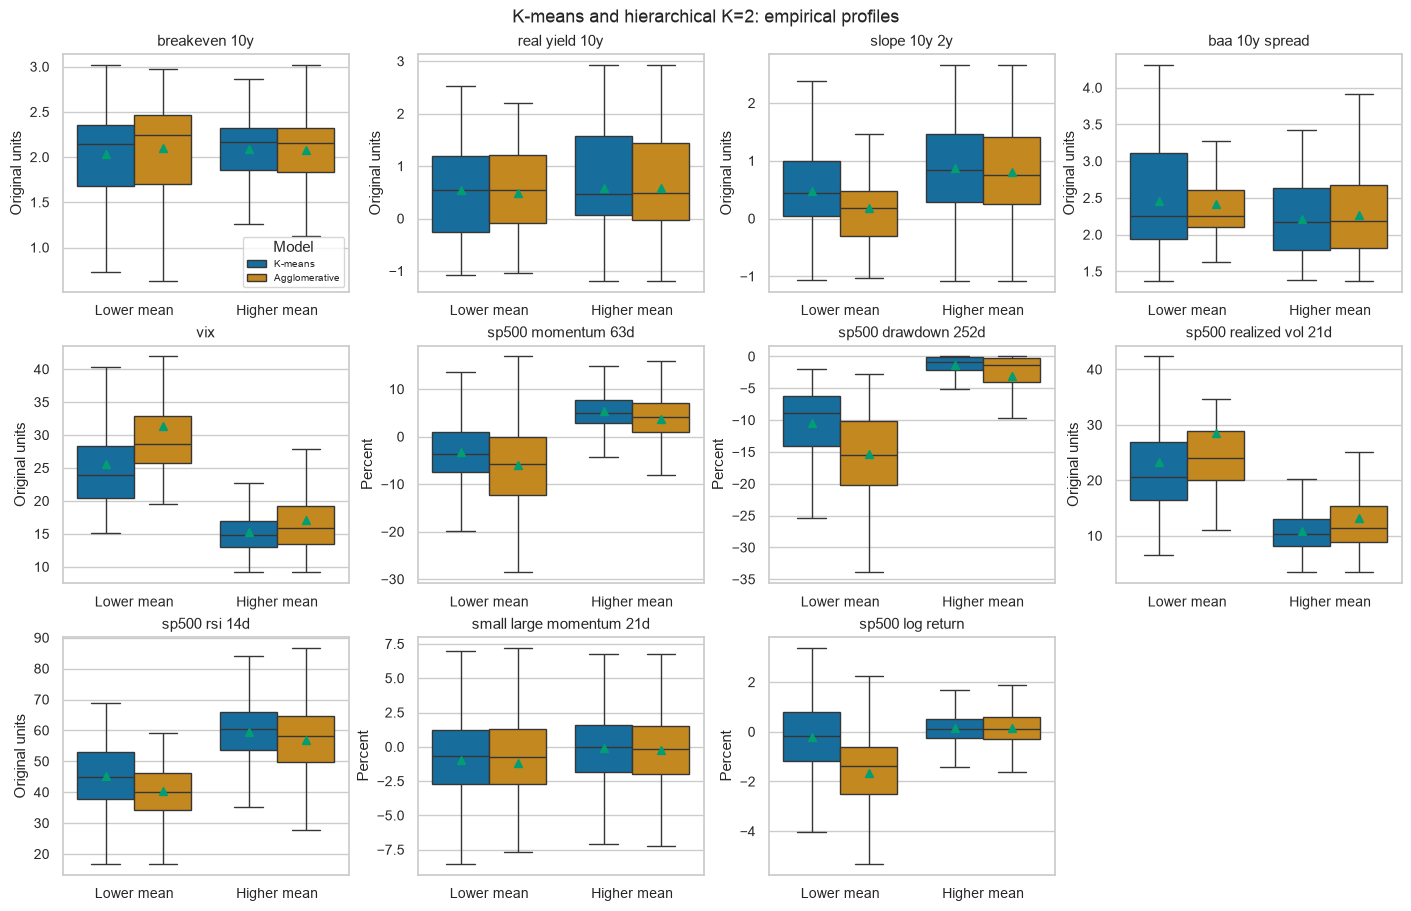

In [23]:
comparison_plot = comparison_profiles.copy()
comparison_plot[percent_columns] *= 100
fig, axes = plt.subplots(3, 4, figsize=(14, 9), layout="constrained")
for ax, variable in zip(axes.flat, df.columns):
    sns.boxplot(data=comparison_plot, x="Profile", y=variable, hue="Model",
                order=profile_order, hue_order=comparison_models, palette="colorblind",
                showmeans=True, showfliers=False, ax=ax)
    ax.set(title=variable.replace("_", " "), xlabel="",
           ylabel="Percent" if variable in percent_columns else "Original units")
    if ax is not axes.flat[0]:
        ax.get_legend().remove()
axes.flat[0].legend(fontsize=7, title="Model")
for ax in axes.flat[len(df.columns):]:
    ax.set_visible(False)
fig.suptitle("K-means and hierarchical K=2: empirical profiles")
fig.savefig(output_dir / "kmeans_hierarchical_boxplots.png", dpi=160)
plt.show()


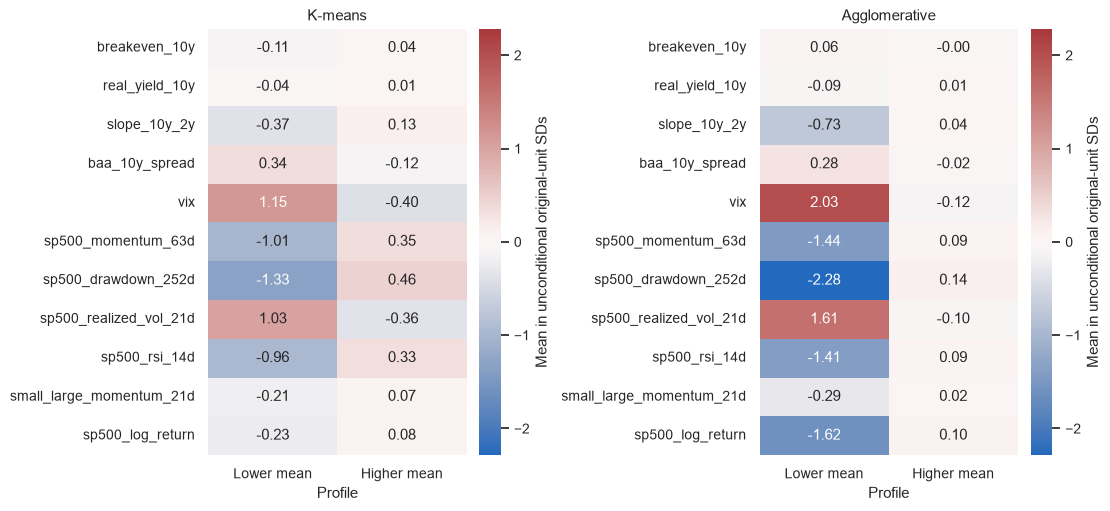

In [24]:
comparison_mean_z = (comparison_means - df.mean()) / df.std(ddof=0)
limit = np.abs(comparison_mean_z.to_numpy()).max()
fig, axes = plt.subplots(1, 2, figsize=(11, 5), layout="constrained")
for ax, name in zip(axes, comparison_models):
    table = comparison_mean_z.loc[name].reindex(profile_order).T
    sns.heatmap(table, annot=True, fmt=".2f", cmap="vlag", center=0,
                vmin=-limit, vmax=limit, ax=ax,
                cbar_kws={"label": "Mean in unconditional original-unit SDs"})
    ax.set(title=name, xlabel="Profile", ylabel="")
fig.savefig(output_dir / "kmeans_hierarchical_mean_profiles.png", dpi=160)
plt.show()


### Separation and sensitivity, kept distinct

Both standard fits assign every date. Compare group populations and the existing PCA95/robust fixed-settings checks alongside silhouette. The mean-profile magnitudes above do not determine the selection: returns helped construct the groups, and a more extreme contrast is not automatically better for EP.

In [25]:
ep_model_comparison = selected.loc[selected["Model"].isin(comparison_models),
    ["Model", "Run", "Silhouette_sample", "Silhouette_full", "Min_size", "Coverage_pct", "Seed_stability_ARI"]].set_index("Model")
ep_model_comparison["Smallest group (%)"] = 100 * ep_model_comparison["Min_size"] / len(df)
calibration_fits = all_fits.loc[all_fits["Stage"].eq("Calibration")].set_index(["Model", "Calibration"])
for calibration in ["PCA95", "Robust"]:
    checks = calibration_fits.xs(calibration, level="Calibration")
    ep_model_comparison[f"{calibration} ARI"] = checks["ARI_vs_standard"]
    ep_model_comparison[f"{calibration} min rows"] = checks["Min_size"]
    ep_model_comparison[f"{calibration} eligible"] = checks["Eligible"]
display(ep_model_comparison.drop(columns="Run").round(3))

kmeans_run = selected.loc[selected["Model"].eq("K-means"), "Run"].iloc[0]
hierarchical_run = selected.loc[selected["Model"].eq("Agglomerative"), "Run"].iloc[0]
print(f"Membership agreement between the two standard fits: ARI = {adjusted_rand_score(assignments[kmeans_run], assignments[hierarchical_run]):.3f}")
membership_table = comparison_profiles.pivot(columns="Model", values="Profile")
pd.crosstab(membership_table["K-means"], membership_table["Agglomerative"])


Membership agreement between the two standard fits: ARI = 0.218
Out[25]: 
Agglomerative  Higher mean  Lower mean
K-means                               
Higher mean           2700           0
Lower mean             721         209


,Silhouette_sample,Silhouette_full,Min_size,Coverage_pct,Seed_stability_ARI,Smallest group (%),PCA95 ARI,PCA95 min rows,PCA95 eligible,Robust ARI,Robust min rows,Robust eligible
Model,,,,,,,,,,,,
K-means,0.269,0.273,930,100.0,1.0,25.620,1.000,930,True,0.836,791,True
Agglomerative,0.328,0.332,209,100.0,NaN,5.758,0.058,7,False,0.254,34,False


## Decision: standard-scaled K-means K=2 for the EP demonstration

Use the **fixed eleven inputs, selective logs, StandardScaler, all eleven informative PCs, and K-means K=2 with 20 starts and seed 1**. Keep complete-linkage hierarchical K=2 as the silhouette winner and an alternative stress partition in the comparison.

This is an **application choice after reviewing diagnostics**, not a claim that K-means won the original silhouette rule. Hierarchical clustering has the higher full-sample silhouette (0.332 versus 0.273), but K-means has substantially larger minimum profile populations (930 versus 209 dates), unchanged labels under PCA95, and an eligible robust calibration with ARI 0.836. Both hierarchical calibration checks fail the minimum population screen and have low agreement with its standard fit. These checks favour K-means for the next EP demonstration, where cluster moments supply the views. They do not prove lower moment-estimation error or superior EP probabilities.

All 209 dates in the hierarchical lower-mean group fall within the 930-date K-means lower-mean group: the hierarchy isolates a more severe subset rather than an unrelated state.

The financial profiles support a broad stress-versus-calmer interpretation for K-means: mean daily log returns of approximately -0.197% and +0.135%, daily simple-return volatilities of 1.733% and 0.670%, and CVaR95 losses of 4.028% and 1.332%. The hierarchical lower-mean group has a much more negative mean log return (-1.673%) and about 90% negative-return days. Breakeven inflation and real-yield means differ little in both partitions, so these are mainly equity-risk profiles rather than a broad macro regime taxonomy.

Keep the **standard** K-means fit as the EP reference; the robust fit is a sensitivity check. The fitted IDs remain unchanged. Include the return in clustering as declared, but **exclude it from the ten-feature EP mean/variance views**. The primary application remains contemporaneous and descriptive. The EP section below implements this choice. A controlled comparison with threshold-based views remains a separate evaluation.

In [26]:
ep_choice = selected.loc[selected["Model"].eq("K-means")].iloc[0]
ep_labels = pd.Series(assignments[ep_choice["Run"]], index=df.index, name="Cluster")
ep_features = scaled_df.drop(columns="sp500_log_return")
ep_view_means = ep_features.groupby(ep_labels).mean()
ep_view_variances = ep_features.groupby(ep_labels).var(ddof=0)

comparison_risk.to_csv(output_dir / "kmeans_hierarchical_equity_profiles.csv", index=False)
comparison_means.to_csv(output_dir / "kmeans_hierarchical_profile_means.csv")
comparison_stds.to_csv(output_dir / "kmeans_hierarchical_profile_stds.csv")
ep_model_comparison.to_csv(output_dir / "ep_model_comparison.csv")
ep_labels.to_csv(output_dir / "ep_selected_assignments.csv", index_label="date")
ep_view_means.to_csv(output_dir / "ep_view_means.csv")
ep_view_variances.to_csv(output_dir / "ep_view_variances.csv")
ep_configuration = {"model": ep_choice["Model"], "run": ep_choice["Run"],
    "parameters": ep_choice["Parameters"], "inputs": df.columns.tolist(), "log_columns": log_columns,
    "scaling": "StandardScaler", "fit_dimensions": int(ep_choice["Fit_dimensions"]),
    "view_features": ep_features.columns.tolist(), "view_units": "standard-scaled selectively transformed features",
    "score_winner": score_winner["Model"], "reason": "application choice based on profile populations and calibration stability",
    "ep_solved": False}
(output_dir / "ep_configuration.json").write_text(json.dumps(ep_configuration, indent=2))
print("EP demonstration choice: standard-scaled K-means, K=2; ten view features, excluding S&P return.")
display(comparison_risk.set_index(["Model", "Profile", "Cluster"]).round(3))


EP demonstration choice: standard-scaled K-means, K=2; ten view features, excluding S&P return.


Rows  Share (%)  ...  CVaR 90 (%)  CVaR 95 (%)
Model         Profile     Cluster                   ...                          
K-means       Lower mean  0         930     25.620  ...        3.194        4.028
              Higher mean 1        2700     74.380  ...        1.057        1.332
Agglomerative Higher mean 0        3421     94.242  ...        1.358        1.705
              Lower mean  1         209      5.758  ...        5.128        6.378

[4 rows x 8 columns]

## Entropy Pooling from the K-means K=2 profiles

Follow the Vorobets/Fortitudo [Section 3.2.1 EP/FFR example](https://github.com/fortitudo-tech/pcrm-book), as in notebook 02. Keep **standard-scaled K-means K=2** from the fixed eleven-input comparison. The S&P return entered clustering but is **excluded from all ten EP conditioning views**.

Each cluster supplies its conditioning-feature means and population variances. Means are equality views; second moments have upper bounds `variance + mean²`. The prior has exponential decay with half-life equal to half the sample. EP reweights **all historical dates**; it does not discard observations outside the target cluster.

Views use the transformed, standardized features: VIX and realized-volatility views therefore concern **log-level moments**, not their original-level moments. Other conditioning features retain their saved transformations before scaling. The S&P return moments emerge from the weights and are not imposed.


In [27]:
import fortitudo.tech as ft

ep_dir = output_dir / "ep"
ep_dir.mkdir(exist_ok=True)
ep_features = scaled_df.drop(columns="sp500_log_return")
ep_values = ep_features.to_numpy()
states_vector = ep_labels.to_numpy()
ep_states = np.unique(states_vector)
p_exp = ft.exp_decay_probs(ep_features, half_life=len(ep_values) / 2)

A = np.vstack([np.ones(len(ep_values)), ep_values.T])
G = ep_values.T ** 2


In [28]:
states_prob, ep_checks = [], []
for state in ep_states:
    cluster = ep_values[states_vector == state]
    mu = cluster.mean(axis=0)
    variance = cluster.var(axis=0)
    b = np.r_[1, mu][:, None]
    h = (variance + mu**2)[:, None]

    q = ft.entropy_pooling(p_exp, A, b, G, h)
    q = q / q.sum()
    states_prob.append(q)
    positive_q = q[q > 0]
    ep_checks.append({"Cluster profile": state,
        "Max mean error": np.abs(A @ q - b).max(),
        "Max bound violation": np.maximum(G @ q - h, 0).max(),
        "Entropy-effective scenarios": np.exp(-np.sum(positive_q * np.log(positive_q)))})

states_prob = np.hstack(states_prob)
ep_checks = pd.DataFrame(ep_checks).set_index("Cluster profile")
assert np.isfinite(states_prob).all() and (states_prob >= 0).all()
assert np.allclose(states_prob.sum(axis=0), 1)
assert ep_checks[["Max mean error", "Max bound violation"]].to_numpy().max() < 1e-5
ep_checks


Out[2]: 
                 Max mean error  ...  Entropy-effective scenarios
Cluster profile                  ...                             
0                  4.708766e-07  ...                  1297.661213
1                  2.504437e-07  ...                  2900.245319

[2 rows x 3 columns]


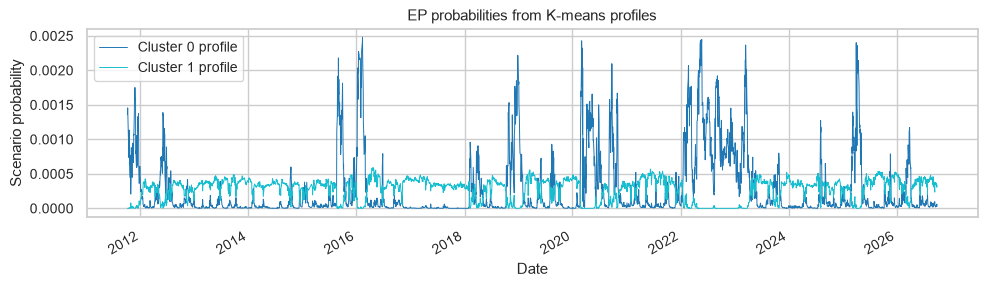

In [29]:
ep_probabilities = pd.DataFrame(states_prob, index=df.index,
                               columns=[f"Cluster {state} profile" for state in ep_states])
ax = ep_probabilities.plot(figsize=(10, 3), colormap="tab10", linewidth=0.7)
ax.set(title="EP probabilities from K-means profiles", xlabel="Date", ylabel="Scenario probability")
ax.figure.tight_layout()
ax.figure.savefig(ep_dir / "ep_probabilities.png", dpi=160)
plt.show()


### State-dependent resampling

Start 10,000 paths in each cluster and simulate 21 observations using Fortitudo's Fully Flexible Resampling. Each step samples a historical row from the current state's EP probabilities, takes its return, and updates the state to that row's K-means label. The matrix below is implied by those weights and labels; it is not a transition estimate from consecutive historical dates.

In this fit, cluster 0 is the lower-return/higher-risk profile and cluster 1 is the calmer profile. Cluster IDs need not match those in notebook 02.


In [30]:
transition = np.array([
    [states_prob[states_vector == next_state, state].sum() for next_state in ep_states]
    for state in ep_states
])
transition_table = pd.DataFrame(transition,
    index=[f"From cluster {state}" for state in ep_states],
    columns=[f"To cluster {state}" for state in ep_states])
transition_table.round(4)


Out[4]: 
                To cluster 0  To cluster 1
From cluster 0        0.8533        0.1467
From cluster 1        0.0444        0.9556


In [31]:
asset_returns = df[["sp500_log_return"]]
resampler = ft.FullyFlexibleResampling(asset_returns)
S, H = 10000, 21
np.random.seed(0)
log_paths, daily_simulations, simulations = {}, {}, {}

for state in ep_states:
    paths = resampler.simulate(S, H, states_prob, states_vector, initial_state=state)
    name = f"Initial cluster {state}"
    log_paths[name] = paths[:, 0, :]
    daily_simulations[name] = np.expm1(paths[:, 0, 0])
    simulations[name] = np.expm1(paths[:, 0, :].sum(axis=1))

simulated_daily_returns = pd.DataFrame(daily_simulations)
simulated_returns = pd.DataFrame(simulations)


### One-day and 21-day simple returns

Convert the sampled log returns to simple returns: `expm1(r)` for one day and `expm1(sum(r))` for 21 days. The left plot is the EP-weighted one-day historical distribution; the right plot uses the simulated 21-day returns, allowing state changes during each path.


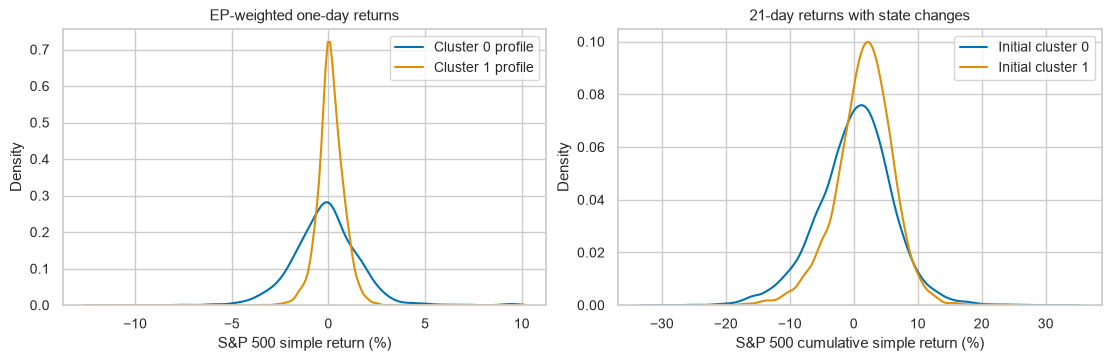

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
for state in ep_states:
    sns.kdeplot(x=100 * np.expm1(asset_returns.iloc[:, 0]), weights=states_prob[:, state],
                label=f"Cluster {state} profile", ax=axes[0])
    sns.kdeplot(x=100 * simulated_returns[f"Initial cluster {state}"],
                label=f"Initial cluster {state}", ax=axes[1])
axes[0].set(title="EP-weighted one-day returns", xlabel="S&P 500 simple return (%)")
axes[1].set(title="21-day returns with state changes", xlabel="S&P 500 cumulative simple return (%)")
for ax in axes:
    ax.legend()
fig.savefig(ep_dir / "sp500_return_distributions.png", dpi=160)
plt.show()


In [33]:
return_samples = pd.concat({"1 day": simulated_daily_returns, "21 days": simulated_returns},
                           axis=1, names=["Horizon", "Initial state"])
ep_return_summary = return_samples.describe(percentiles=[0.05, 0.5, 0.95]).loc[
    ["mean", "std", "5%", "50%", "95%"]
].T * 100
ep_return_summary["Loss probability (%)"] = 100 * return_samples.lt(0).mean()

exposures = np.eye(return_samples.shape[1])
for alpha in [0.90, 0.95]:
    cvars = ft.portfolio_cvar(exposures, return_samples, alpha=alpha, demean=False)
    ep_return_summary[f"CVaR {alpha:.0%} (%)"] = 100 * cvars[0]

ep_return_summary = ep_return_summary.rename(columns={
    "mean": "Mean (%)", "std": "Std (%)", "5%": "5th percentile (%)",
    "50%": "Median (%)", "95%": "95th percentile (%)"})
ep_return_summary.round(2)


Out[7]: 
                           Mean (%)  Std (%)  ...  CVaR 90% (%)  CVaR 95% (%)
Horizon Initial state                         ...                            
1 day   Initial cluster 0     -0.15     1.70  ...          3.11          3.81
        Initial cluster 1      0.13     0.67  ...          1.08          1.38
21 days Initial cluster 0      0.18     5.88  ...         10.81         13.20
        Initial cluster 1      1.60     4.54  ...          7.23          9.26

[4 rows x 8 columns]


The table contains **simple-return** statistics for both initial states and both horizons, using the same 10,000 paths per initial state. Its one-day values have simulation sampling variation; the one-day density plot uses the posterior historical weights directly. Volatility in the table is the standard deviation at the stated horizon, not an annualized number.

CVaR is calculated with `fortitudo.tech.portfolio_cvar`, using `demean=False`: 90% CVaR measures mean loss in the worst 10% of outcomes, and 95% CVaR in the worst 5%. Positive values represent losses. At 21 days the cluster specifies the **initial state**, not a state held fixed for the whole path.

These are model-implied scenario distributions from the fitted full-sample pipeline, not validated forecasts. The variance views are caps; achieved conditioning-feature variances can be below their targets. Neither the S&P mean nor its variance or CVaR was specified as an EP constraint.


In [34]:
ep_probabilities.to_csv(ep_dir / "posterior_probabilities.csv", index_label="date")
pd.DataFrame(p_exp, index=df.index, columns=["Prior probability"]).to_csv(ep_dir / "prior_probabilities.csv", index_label="date")
ep_checks.to_csv(ep_dir / "ep_diagnostics.csv")
transition_table.to_csv(ep_dir / "transition_matrix.csv")
simulated_daily_returns.to_csv(ep_dir / "one_day_simple_returns.csv", index=False)
simulated_returns.to_csv(ep_dir / "21_day_simple_returns.csv", index=False)
ep_return_summary.to_csv(ep_dir / "return_summary.csv")
np.savez_compressed(ep_dir / "log_return_paths.npz", **log_paths)
ep_configuration.update(ep_solved=True, half_life=len(ep_values) / 2,
                        paths_per_initial_state=S, horizon=H, simulation_seed=0,
                        mean_views="equalities", variance_views="second-moment upper bounds",
                        return_units="simple returns at both horizons")
(output_dir / "ep_configuration.json").write_text(json.dumps(ep_configuration, indent=2))
print("EP complete: ten conditioning features, no S&P return views; 1-day and 21-day simple returns.")
display(ep_return_summary.round(2))


EP complete: ten conditioning features, no S&P return views; 1-day and 21-day simple returns.


Mean (%)  Std (%)  ...  CVaR 90% (%)  CVaR 95% (%)
Horizon Initial state                         ...                            
1 day   Initial cluster 0     -0.15     1.70  ...          3.11          3.81
        Initial cluster 1      0.13     0.67  ...          1.08          1.38
21 days Initial cluster 0      0.18     5.88  ...         10.81         13.20
        Initial cluster 1      1.60     4.54  ...          7.23          9.26

[4 rows x 8 columns]